# Figure 4, Panel E

Lineplots across timeof median ± IQR expression (Log2(TPM+1), Z-scored and normalized to vehicle) for IFNg and Dex-induced genes, separated into early (1h) and late (6h) induced categories and colored to indicate whether treated with stimulus alone or pretreated with BAFinh.

P-values from one-sided wilcoxon rank-sum tests

*Output: panelE_lineplot_median_iqr.pdf*

# Setup

In [1]:
#load packages
library(tidyverse)
library(patchwork)
library(here)
here::i_am("figures/Figure4/Panel_E/PanelE_lineplot.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      patchwork_1.3.0 lubridate_1.9.4 forcats_1.0.0  
 [5] stringr_1.5.1   dplyr_1.1.4     purrr_1.0.2     readr_2.1.5    
 [9] tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    ba

# Load data

In [2]:

#load sample data (col.data), gene metadata (row.data) and table of TPMs
# TPMs
tpms <- read.delim(
  here(
    "figures", "Figure4",
    "IFNy_Dex_DEGs_TPMs.tsv"
  ),
  sep = "\t"
)

# gene-level metadata
row.data <- read.delim(
  here(
    "figures", "Figure4",
    "IFNy_Dex_DEGs_rowdata.tsv"
  ),
  sep = "\t"
)

# sample-level metadata
col.data <- read.delim(
  here(
    "figures", "Figure4",
    "IFNy_Dex_DEGs_coldata.tsv"
  ),
  sep = "\t"
)

#read in DEGs
ifn_1h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus",
    "IFNy_1h_DEGs.tsv"
  ),
  sep = "\t"
)

ifn_6h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus",
    "IFNy_6h_DEGs.tsv"
  ),
  sep = "\t"
)

dex_1h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus",
    "Dex_1h_DEGs.tsv"
  ),
  sep = "\t"
)

dex_6h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus",
    "Dex_6h_DEGs.tsv"
  ),
  sep = "\t"
)



# Define 1h and 6h induced gene sets

In [3]:
ifn_up_1h <- which((ifn_1h$change == "up" & ifn_6h$change != "up") | (ifn_1h$change == "up" & ifn_6h$change == "up"))
length(ifn_up_1h)
ifn_up_6h <-  which((ifn_1h$change != "up" & ifn_6h$change == "up"))
length(ifn_up_6h)

dex_up_1h <- which((dex_1h$change == "up" & dex_6h$change != "up") | (dex_1h$change == "up" & dex_6h$change == "up"))
length(dex_up_1h)
dex_up_6h <- which((dex_1h$change != "up" & dex_6h$change == "up"))
length(dex_up_6h)

[1] 41

[1] 114

[1] 31

[1] 328

# Calculate median and IQR normalized expression

In [8]:
#IFNy
col.data_ifn <- col.data[grep("IFN|Veh",col.data$group),]
tpm_ifn <- tpm[,grep("IFN|Veh",col.data$group)] %>% `colnames<-`(col.data_ifn$group)
head(tpm_ifn)

#average over replicates
tpm_ifn_mean <- data.frame(
    BRM_IFN_1=rowMeans(tpm_ifn[,1:2]),
    IFN_1=rowMeans(tpm_ifn[,3:4]),
    Veh_1=rowMeans(tpm_ifn[,5:6]),
    BRM_IFN_6=rowMeans(tpm_ifn[,7:8]),
    IFN_6=rowMeans(tpm_ifn[,9:10]),
    Veh_6=rowMeans(tpm_ifn[,11:12])
)

#filter to only include IFNy-inducible genes
ifn_inducible <- rbind(tpm_ifn_mean[ifn_up_1h,],tpm_ifn_mean[ifn_up_6h,])
#filter rowdata and add metadata column specifying whether gene is inducible at 1h or 6h
row.data_ifn_inducible <- rbind(row.data[ifn_up_1h,],row.data[ifn_up_6h,]) %>% mutate(category=c(rep("up_1h", 41), rep("up_6h", 114)))

#select only IFNy-induced genes, log-normalize, and Z-score across rows (to control for variability in magnitude of expression)
ifn_inducible_scale <- 
    ifn_inducible %>%
        mutate(Veh=(Veh_1 + Veh_6)/2) %>% #average expression across vehicle treatment timepoints
        select(!c(Veh_1, Veh_6)) %>% 
        +1 %>% log2() %>% #log-normalize
        apply(MARGIN=1,FUN=scale) %>% t() %>% #scale by row
        data.frame() %>% 
        `colnames<-`(c("BRM_IFN_1", "IFN_1","BRM_IFN_6", "IFN_6", "Veh"))
head(ifn_inducible_scale)



,BRM_IFN_T1,BRM_IFN_T1,IFN_T1,IFN_T1,Veh_T1,Veh_T1,BRM_IFN_T6,BRM_IFN_T6,IFN_T6,IFN_T6,Veh_T6,Veh_T6
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,57.89,53.07,55.57,60.77,57.17,60.77,59.02,59.23,60.71,59.59,64.56,57.29
2,12.86,14.88,17.98,10.78,14.29,13.70,23.96,22.85,13.30,16.77,12.54,15.56
3,450.90,401.70,438.32,411.00,396.87,382.82,567.30,581.59,625.20,568.06,456.13,402.24
4,22.17,21.91,25.35,23.60,24.38,20.99,22.66,20.54,18.56,22.07,21.92,25.48
5,9.59,11.00,10.30,11.14,11.55,10.03,19.03,16.87,13.86,12.30,9.96,10.29
6,9.99,10.36,10.14,12.03,9.75,10.69,5.81,8.38,8.01,8.09,11.73,10.44


,BRM_IFN_1,IFN_1,BRM_IFN_6,IFN_6,Veh
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
483,-1.2638350,1.45178770,-0.4317829,0.3204983,-0.07666811
539,-0.6332782,0.46966591,-0.8784482,1.5368443,-0.49478379
542,-0.8011031,0.08494556,-0.1962583,1.6595885,-0.74717259
673,-0.5606593,1.26691531,-0.6226376,0.8772700,-0.96088833
715,-1.3833005,0.21258356,1.2752247,0.4003104,-0.50481816
733,0.4885476,0.56415945,-0.1551696,0.7792746,-1.67681210


In [9]:
#Dex
col.data_dex <- col.data[grep("Dex|Veh",col.data$group),]
tpm_dex <- tpm[,grep("Dex|Veh",col.data$group)] %>% `colnames<-`(col.data_dex$group)
head(tpm_dex)

#average over replicates
tpm_dex_mean <- data.frame(
    BRM_Dex_1=rowMeans(tpm_dex[,1:2]),
    Dex_1=rowMeans(tpm_dex[,3:4]),
    Veh_1=rowMeans(tpm_dex[,5:6]),
    BRM_Dex_6=rowMeans(tpm_dex[,7:8]),
    Dex_6=rowMeans(tpm_dex[,9:10]),
    Veh_6=rowMeans(tpm_dex[,11:12])
)

#filer to only include dexy-inducible genes
dex_inducible <- rbind(tpm_dex_mean[dex_up_1h,],tpm_dex_mean[dex_up_6h,])
#filter rowdata and add metadata column specifying whether gene is inducible at 1h or 6h
row.data_dex_inducible <- rbind(row.data[dex_up_1h,],row.data[dex_up_6h,]) %>% mutate(category=c(rep("up_1h", 31), rep("up_6h", 328)))

#select only dexy-induced genes, log-normalize, and Z-score across rows (to control for variability in magnitude of expression)
dex_inducible_scale <- 
    dex_inducible %>%
        mutate(Veh=(Veh_1 + Veh_6)/2) %>% #average expression across vehicle treatment timepoints
        select(!c(Veh_1, Veh_6)) %>% 
        +1 %>% log2() %>% #log-normalize
        apply(MARGIN=1,FUN=scale) %>% t() %>% #scale by row
        data.frame() %>% 
        `colnames<-`(c("BRM_Dex_1", "Dex_1","BRM_Dex_6", "Dex_6", "Veh"))
head(dex_inducible_scale)


,BRM_Dex_T1,BRM_Dex_T1,Dex_T1,Dex_T1,Veh_T1,Veh_T1,BRM_Dex_T6,BRM_Dex_T6,Dex_T6,Dex_T6,Veh_T6,Veh_T6
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,60.73,56.71,58.87,54.82,57.17,60.77,60.43,60.89,63.03,57.85,64.56,57.29
2,13.33,12.32,16.15,14.89,14.29,13.70,22.93,25.07,12.13,14.80,12.54,15.56
3,402.33,363.47,380.40,356.99,396.87,382.82,218.72,235.92,269.01,241.99,456.13,402.24
4,22.11,20.70,22.21,24.71,24.38,20.99,17.08,19.47,16.21,18.05,21.92,25.48
5,10.23,10.87,9.65,10.69,11.55,10.03,17.28,18.26,11.32,10.96,9.96,10.29
6,9.06,11.37,10.87,10.42,9.75,10.69,5.38,8.30,12.39,12.57,11.73,10.44


,BRM_Dex_1,Dex_1,BRM_Dex_6,Dex_6,Veh
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
698,-0.9434756,1.1035818,-0.7794845,1.0487934,-0.4294151
715,-1.1805084,1.0547931,0.4115581,0.6581960,-0.9440389
1007,0.6839854,0.5032473,-0.9782456,0.9679112,-1.1768983
1386,0.5913606,0.2542930,0.4617427,0.4683043,-1.7757006
1447,-0.7015314,0.1633979,0.9842654,0.8753101,-1.3214419
1702,-0.3639225,0.8738031,-0.6100564,1.2177442,-1.1175683


# Generate plots

In [10]:
#IFNg
lineplot_ifn_median <- ifn_inducible_scale %>% 
    apply(MARGIN=2, FUN=function(x) x - ifn_inducible_scale$Veh) %>%
    data.frame() %>% 
    mutate(cat=row.data_ifn_inducible$category, Veh_BRM=Veh) %>% 
    pivot_longer(!cat) %>% #convert to tidy format
    mutate(BAFinh=grepl("BRM", name), #separate into -/+ BAFinh
           time=as.numeric(ifelse(grepl("Veh", name), 0, gsub("^.*_","",name)))) %>% 
    group_by(cat,BAFinh,time) %>% 
            summarize(median=median(value), pctile_25 = quantile(value,0.25), pctile_75=quantile(value,0.75)) %>% #summarize data
    ggplot() +
        geom_ribbon(aes(x=time,ymin=pctile_25, ymax=pctile_75, group=BAFinh, fill=BAFinh), alpha=.1) + 
        geom_line(aes(x=time,y=median, group=BAFinh, color=BAFinh), linewidth=1) +
        geom_point(aes(x=time,y=median, group=BAFinh, color=BAFinh), size=2) +
        ylab("Log2(TPM+1), Z-score") +
        xlab("IFNy treatment (h)") +
        scale_color_manual(values=c("#1c9e77", "darkgrey")) +
        scale_fill_manual(values=c("#1c9e77", "darkgrey"))  +
        ggtitle(paste("IFNy-inducible genes, n =", nrow(ifn_inducible_scale))) +
        facet_wrap(~cat, ncol=1) +
        scale_y_continuous(breaks=c(0,1,2)) +
        scale_x_continuous(breaks=c(0,1,6))

#Dex
lineplot_dex_median <- dex_inducible_scale %>% 
    apply(MARGIN=2, FUN=function(x) x - dex_inducible_scale$Veh) %>%
    data.frame() %>% 
    mutate(cat=row.data_dex_inducible$category, Veh_BRM=Veh) %>% 
    pivot_longer(!cat) %>% #convert to tidy format
    mutate(BAFinh=grepl("BRM", name), #separate into -/+ BAFinh
           time=as.numeric(ifelse(grepl("Veh", name), 0, gsub("^.*_","",name)))) %>% 
    group_by(cat,BAFinh,time) %>% 
            summarize(median=median(value), pctile_25 = quantile(value,0.25), pctile_75=quantile(value,0.75)) %>% #summarize data
    ggplot() +
        geom_ribbon(aes(x=time,ymin=pctile_25, ymax=pctile_75, group=BAFinh, fill=BAFinh), alpha=.1) + 
        geom_line(aes(x=time,y=median, group=BAFinh, color=BAFinh), linewidth=1) +
        geom_point(aes(x=time,y=median, group=BAFinh, color=BAFinh), size=2) +
        ylab("Log2(TPM+1), Z-score") +
        xlab("Dex treatment (h)") +
        scale_color_manual(values=c("#5791c9", "darkgrey")) +
        scale_fill_manual(values=c("#5791c9", "darkgrey"))  +
        ggtitle(paste("Dex-inducible genes, n =", nrow(dex_inducible_scale))) +
        facet_wrap(~cat, ncol=1) +
        scale_y_continuous(breaks=c(0,1,2)) +
        scale_x_continuous(breaks=c(0,1,6))

`summarise()` has grouped output by 'cat', 'BAFinh'. You can override using the
`.groups` argument.
`summarise()` has grouped output by 'cat', 'BAFinh'. You can override using the
`.groups` argument.


# Assemble figure panel

Saving 8 x 7 in image


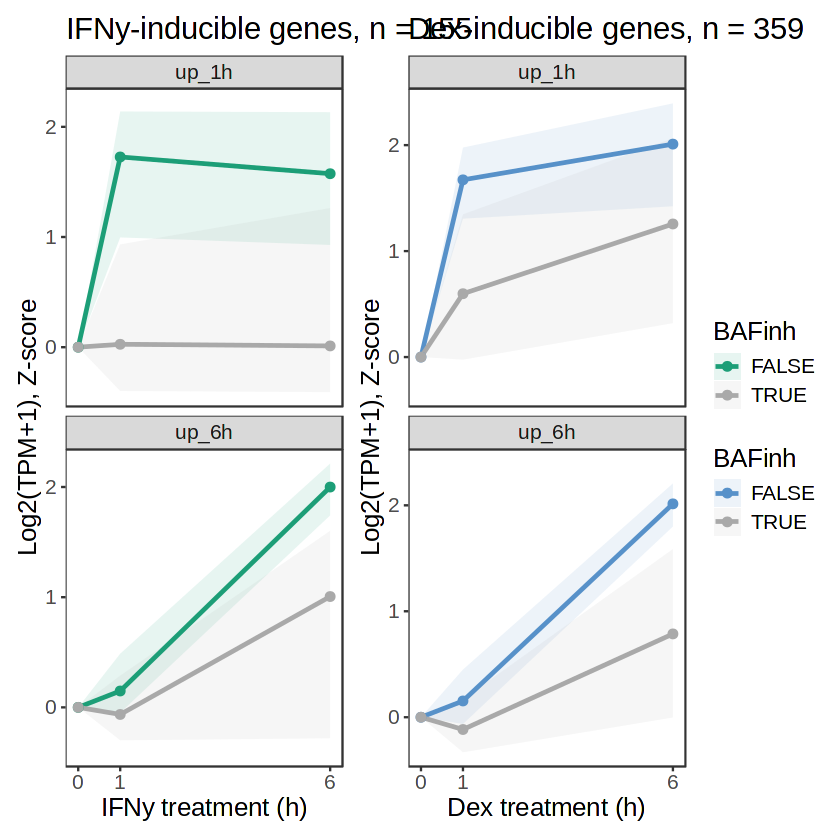

In [11]:
(lineplot_ifn_median | lineplot_dex_median) + plot_layout(guides="collect")
ggsave("panelE_lineplot_median_iqr.pdf", width=8)

# Statistics

In [12]:
#stats (IFNy)
#wilcoxon rank-sum test within 1h and 6h induced sets - is expression lower with BAFinh?

ifn_for_stats <- ifn_inducible_scale %>% 
    apply(MARGIN=2, FUN=function(x) x - ifn_inducible_scale$Veh) %>%
    data.frame() %>% 
    mutate(cat=row.data_ifn_inducible$category, Veh_BRM=Veh)

wilcox.test(ifn_for_stats[ifn_for_stats$cat=="up_1h",]$BRM_IFN_1, ifn_for_stats[ifn_for_stats$cat=="up_1h",]$IFN_1, alternative="less")$p.value
wilcox.test(ifn_for_stats[ifn_for_stats$cat=="up_1h",]$BRM_IFN_6, ifn_for_stats[ifn_for_stats$cat=="up_1h",]$IFN_6, alternative="less")$p.value
wilcox.test(ifn_for_stats[ifn_for_stats$cat=="up_6h",]$BRM_IFN_1, ifn_for_stats[ifn_for_stats$cat=="up_6h",]$IFN_1, alternative="less")$p.value
wilcox.test(ifn_for_stats[ifn_for_stats$cat=="up_6h",]$BRM_IFN_6, ifn_for_stats[ifn_for_stats$cat=="up_6h",]$IFN_6, alternative="less")$p.value       

#stats (Dex)
#wilcoxon rank-sum test within 1h and 6h induced sets - is expression lower with BAFinh?

dex_for_stats <- dex_inducible_scale %>% 
    apply(MARGIN=2, FUN=function(x) x - dex_inducible_scale$Veh) %>%
    data.frame() %>% 
    mutate(cat=row.data_dex_inducible$category, Veh_BRM=Veh)

wilcox.test(dex_for_stats[dex_for_stats$cat=="up_1h",]$BRM_Dex_1, dex_for_stats[dex_for_stats$cat=="up_1h",]$Dex_1, alternative="less")$p.value
wilcox.test(dex_for_stats[dex_for_stats$cat=="up_1h",]$BRM_Dex_6, dex_for_stats[dex_for_stats$cat=="up_1h",]$Dex_6, alternative="less")$p.value
wilcox.test(dex_for_stats[dex_for_stats$cat=="up_6h",]$BRM_Dex_1, dex_for_stats[dex_for_stats$cat=="up_6h",]$Dex_1, alternative="less")$p.value
wilcox.test(dex_for_stats[dex_for_stats$cat=="up_6h",]$BRM_Dex_6, dex_for_stats[dex_for_stats$cat=="up_6h",]$Dex_6, alternative="less")$p.value       

[1] 1.275741e-08

[1] 6.669162e-07

[1] 3.67233e-05

[1] 3.375423e-22

[1] 2.915252e-05

[1] 0.002612782

[1] 1.042555e-17

[1] 2.496969e-59